# Del índice al precio: valor del suelo en pesos por m²

Los notebooks anteriores trabajaban con el **IVS**, un proxy construido a partir
de la morfología porque el GeoJSON de construcciones no trae ningún campo
monetario. Este flujo es distinto: trae el **valor comercial real del suelo**
publicado por Catastro Bogotá y lo usa para tres cosas.

1. **Traducir el IVS a pesos** y medir cuánto se le puede creer.
2. **Ver dónde se está valorizando la ciudad** entre 2017 y 2026.
3. **Ubicar las zonas empresariales** según el uso económico predominante.

Los notebooks previos quedan intactos: este es un flujo aparte que no modifica
ni el pipeline ni el IVS.

### De dónde salen los datos

Dos capas del servidor de Catastro Bogotá, las mismas que ya usabas para
descargar la información:

| Capa | Campo | Qué es |
|---|---|---|
| `catastro/valorreferencia` | `V_REF` | mediana del valor comercial del suelo, en COP por m² de **terreno**, por manzana |
| `catastro/usopredominante` | `GRUPOUSOECON` | grupo de uso económico predominante de la manzana |

Ambas traen `MANCODIGO`, el código de manzana de 9 dígitos, que es exactamente
la clave que el pipeline construye a partir de `LOTECODIGO`. La unión es directa,
sin geocodificar ni cruzar direcciones.

> **Qué es y qué no es `V_REF`.** Es el valor **del terreno** por m², mediano
> **por manzana**, no el avalúo de un predio ni el precio de lo construido. Sirve
> para comparar zonas, no para tasar un inmueble concreto.

**Requisito**: haber ejecutado las etapas 01 y 02 del pipeline, y conexión a
internet la primera vez (después queda en caché).

## 0. Preparación

In [1]:
import json
import ssl
import sys
import time
import unicodedata
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupShuffleSplit

%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

print("raiz del proyecto:", ROOT)

raiz del proyecto: C:\Users\Usuario\Proyectos\Catastro_ML


### Parámetros editables

In [2]:
ANIO = 2026                  # año de referencia para valor y uso
ANIO_BASE = 2017             # año inicial para medir valorizacion
FORZAR_DESCARGA = False      # True vuelve a bajar aunque exista la cache
INFLACION_ANUAL_PROM = None  # p. ej. 0.055 para ver la valorizacion en terminos reales

GUARDAR_TABLAS = True
GUARDAR_FIGURAS = False

# archivos de cache (no se versionan: viven en data/processed)
F_VREF = C.PROC_DIR / "catastro_valor_referencia.csv.gz"
F_USO = C.PROC_DIR / "catastro_uso_predominante.csv.gz"
F_SALIDA = C.PROC_DIR / "manzanas_valor_pesos.csv.gz"

BASE_ARCGIS = "https://serviciosgis.catastrobogota.gov.co/arcgis/rest/services"
PAGINA = 2000                # maxRecordCount del servicio

# usos que se consideran "empresariales"
USOS_EMPRESA = ["COMERCIO Y OFICINAS", "INDUSTRIAL", "BODEGAS"]

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
AZUL, VERDE, NARANJA, ROJO, AMARILLO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#e9c46a", "#9aa5ab"
CMAP_VALOR = "RdYlBu_r"
ASPECTO = 1 / np.cos(np.radians(4.65))

def guardar_fig(fig, archivo):
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / archivo, facecolor="white")

def guardar_tabla(tabla, archivo, **kw):
    if GUARDAR_TABLAS:
        tabla.to_csv(C.TAB_DIR / archivo, **kw)

def formato_mapa(ax, titulo=None):
    ax.set_xlim(*C.URB_LON); ax.set_ylim(*C.URB_LAT)
    ax.set_aspect(ASPECTO); ax.set_xlabel("longitud"); ax.grid(alpha=.25)
    if titulo:
        ax.set_title(titulo)

def recorte_urbano(d):
    return d[d["lon"].between(*C.URB_LON) & d["lat"].between(*C.URB_LAT)]

def pesos(x, pos=None):
    "Formatea 7900000 como '7.9 M'."
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

print("parametros cargados | año de referencia:", ANIO)

parametros cargados | año de referencia: 2026


## 1. Descarga desde el servidor de Catastro

El servicio entrega como máximo 2000 registros por petición, así que se pagina.
Son ~215 páginas para los diez años de valores y ~22 para los usos del último
año: unos 4 minutos la primera vez. Después queda en caché y la celda es
instantánea.

In [3]:
_CTX = ssl.create_default_context()
_CTX.check_hostname = False
_CTX.verify_mode = ssl.CERT_NONE

def _consultar(servicio, params, intentos=4):
    "Una peticion al endpoint /query, con reintentos: el servicio devuelve 500 de vez en cuando."
    p = {"f": "json", "returnGeometry": "false"}
    p.update(params)
    url = "%s/%s/MapServer/0/query?%s" % (BASE_ARCGIS, servicio, urllib.parse.urlencode(p))
    for intento in range(intentos):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=120, context=_CTX) as r:
                return json.loads(r.read().decode("utf-8", "replace"))
        except Exception:
            if intento == intentos - 1:
                raise
            time.sleep(2 * (intento + 1))

def descargar_capa(servicio, campos, where="1=1", etiqueta=""):
    "Descarga una capa completa paginando por resultOffset."
    total = len(_consultar(servicio, {"where": where, "returnIdsOnly": "true"}).get("objectIds") or [])
    filas, desplazamiento, t0 = [], 0, time.time()
    while True:
        r = _consultar(servicio, {"where": where, "outFields": ",".join(campos),
                                  "orderByFields": "OBJECTID", "resultOffset": desplazamiento,
                                  "resultRecordCount": PAGINA})
        lote = [f["attributes"] for f in r.get("features", [])]
        if not lote:
            break
        filas.extend(lote)
        desplazamiento += len(lote)
        print("\r   %s %6d / %d  (%.0f s)" % (etiqueta, len(filas), total, time.time() - t0),
              end="", flush=True)
        if len(lote) < PAGINA or not r.get("exceededTransferLimit", False):
            break
    print()
    return pd.DataFrame(filas)

def cargar_o_descargar(ruta, servicio, campos, where="1=1", etiqueta=""):
    if ruta.exists() and not FORZAR_DESCARGA:
        print("   %s: desde cache (%s)" % (etiqueta, ruta.name))
        return pd.read_csv(ruta, dtype={"MANCODIGO": str})
    d = descargar_capa(servicio, campos, where, etiqueta)
    d.to_csv(ruta, index=False)
    return d

print("valor de referencia (2017-2026) y uso predominante (%d)" % ANIO)
vref = cargar_o_descargar(F_VREF, "catastro/valorreferencia",
                          ["MANCODIGO", "V_REF", "ANO"], etiqueta="valores")
uso = cargar_o_descargar(F_USO, "catastro/usopredominante",
                         ["MANCODIGO", "GRUPOUSOECON", "ANO"],
                         where="ANO = timestamp '%d-01-01 00:00:00'" % ANIO, etiqueta="usos   ")

vref["anio"] = pd.to_datetime(vref["ANO"], unit="ms").dt.year
uso["anio"] = pd.to_datetime(uso["ANO"], unit="ms").dt.year
vref = vref.rename(columns={"MANCODIGO": "manzana", "V_REF": "cop_m2"})[["manzana", "anio", "cop_m2"]]

def sin_tildes(s):
    "El servicio mezcla 'DEPOSITOS' y 'DEPÓSITOS': se normaliza."
    if pd.isna(s):
        return s
    return "".join(c for c in unicodedata.normalize("NFD", str(s))
                   if unicodedata.category(c) != "Mn").upper().strip()

uso["uso"] = uso["GRUPOUSOECON"].map(sin_tildes)
uso = uso.rename(columns={"MANCODIGO": "manzana"})[["manzana", "uso"]].drop_duplicates("manzana")

print("\nvalores : %d filas, %d manzanas, años %d-%d"
      % (len(vref), vref["manzana"].nunique(), vref["anio"].min(), vref["anio"].max()))
print("usos    : %d manzanas en %d" % (len(uso), ANIO))
vref.head()

valor de referencia (2017-2026) y uso predominante (2026)
   valores: desde cache (catastro_valor_referencia.csv.gz)


   usos   : desde cache (catastro_uso_predominante.csv.gz)

valores : 427839 filas, 44276 manzanas, años 2017-2026
usos    : 43677 manzanas en 2026


,manzana,anio,cop_m2
0,001205015,2017,1100000.0
1,001304045,2017,850000.0
2,001306011,2017,700000.0
3,001310035,2017,660000.0
4,001311010,2017,530000.0


## 2. Unión con las manzanas del proyecto

La clave es el código de manzana. Interesa cuántas de las 38 748 manzanas
modelables del pipeline reciben valor: si la cobertura fuera baja, todo lo que
sigue se sostendría sobre un subconjunto sesgado.

In [4]:
mz = pd.read_csv(C.F_DATASET, dtype={"manzana": str, "sector": str})
mz["valor_cat"] = pd.Categorical(mz["valor_cat"], categories=C.CLASES, ordered=True)

# una manzana puede venir repetida dentro del mismo año: se consolida con la mediana
valor_anio = (vref[vref["anio"] == ANIO]
              .groupby("manzana", as_index=False)["cop_m2"].median())
datos = mz.merge(valor_anio, on="manzana", how="left").merge(uso, on="manzana", how="left")

cobertura = pd.DataFrame({
    "concepto": ["manzanas del pipeline", "con valor de referencia %d" % ANIO,
                 "con uso predominante %d" % ANIO, "con ambos"],
    "manzanas": [len(datos), datos["cop_m2"].notna().sum(), datos["uso"].notna().sum(),
                 (datos["cop_m2"].notna() & datos["uso"].notna()).sum()],
})
cobertura["porcentaje"] = (100 * cobertura["manzanas"] / len(datos)).round(1)
guardar_tabla(cobertura, "t20_cobertura_catastro.csv", index=False)

# a partir de aqui se trabaja con las manzanas que si tienen precio
con_valor = datos[datos["cop_m2"].notna() & (datos["cop_m2"] > 0)].copy()
con_valor["log_cop"] = np.log10(con_valor["cop_m2"])
print("manzanas con precio: %d" % len(con_valor))
cobertura

manzanas con precio: 38018


,concepto,manzanas,porcentaje
0,manzanas del pipeline,38748,100.0
1,con valor de referencia 2026,38018,98.1
2,con uso predominante 2026,38469,99.3
3,con ambos,38018,98.1


## 3. El valor real del suelo

Primero conviene mirar el precio por sí solo, antes de compararlo con nada.

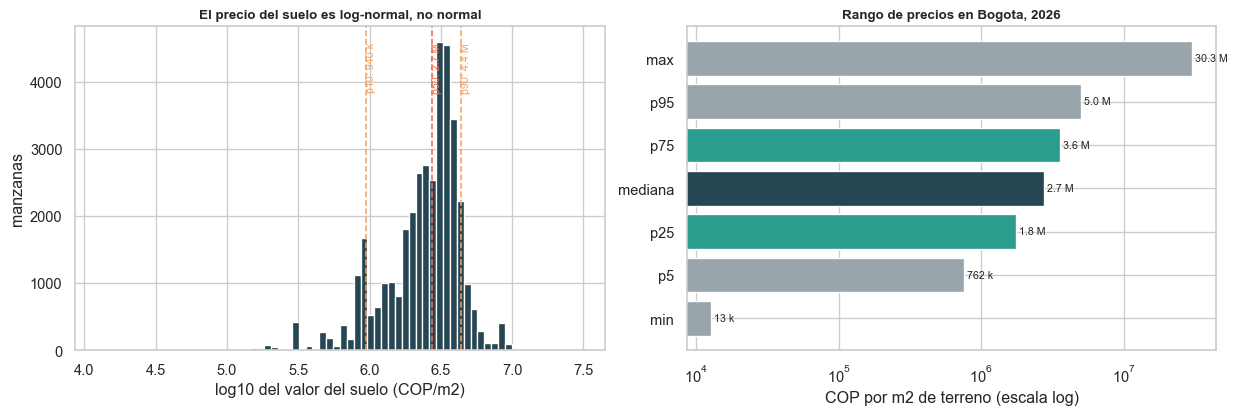

razon entre el 10% mas caro y el 10% mas barato: 4.6 veces


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.hist(con_valor["log_cop"], bins=70, color=AZUL)
for p, color in [(10, NARANJA), (50, ROJO), (90, NARANJA)]:
    v = np.percentile(con_valor["cop_m2"], p)
    ax.axvline(np.log10(v), color=color, ls="--", lw=1.2)
    ax.text(np.log10(v), ax.get_ylim()[1] * 0.95, " p%d: %s" % (p, pesos(v)),
            fontsize=8, color=color, rotation=90, va="top")
ax.set_xlabel("log10 del valor del suelo (COP/m2)")
ax.set_ylabel("manzanas")
ax.set_title("El precio del suelo es log-normal, no normal")

ax = axes[1]
res = con_valor["cop_m2"].describe(percentiles=[.05, .25, .5, .75, .95])
etiquetas = ["min", "p5", "p25", "mediana", "p75", "p95", "max"]
valores = [res["min"], res["5%"], res["25%"], res["50%"], res["75%"], res["95%"], res["max"]]
barras = ax.barh(etiquetas, valores, color=[GRIS, GRIS, VERDE, AZUL, VERDE, GRIS, GRIS])
ax.set_xscale("log")
ax.set_xlabel("COP por m2 de terreno (escala log)")
ax.set_title("Rango de precios en Bogota, %d" % ANIO)
for b, v in zip(barras, valores):
    ax.text(v * 1.05, b.get_y() + b.get_height() / 2, pesos(v), va="center", fontsize=8)

fig.tight_layout()
guardar_fig(fig, "fig30_distribucion_precio.png")
plt.show()

print("razon entre el 10%% mas caro y el 10%% mas barato: %.1f veces"
      % (np.percentile(con_valor["cop_m2"], 90) / np.percentile(con_valor["cop_m2"], 10)))

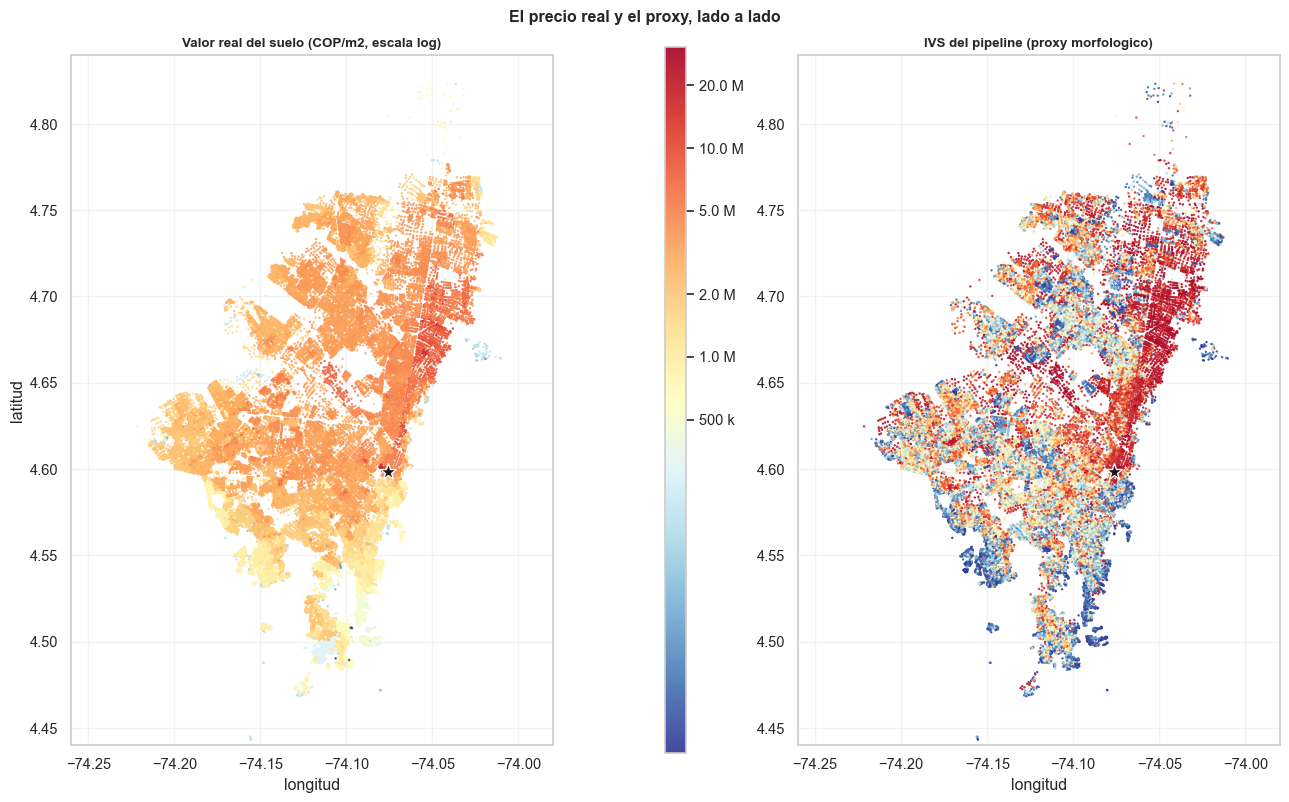

In [6]:
urb = recorte_urbano(con_valor)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 8.5),
                         gridspec_kw={"width_ratios": [1, .045, 1]})

ax = axes[0]
sc = ax.scatter(urb["lon"], urb["lat"], c=urb["log_cop"], s=3.2, cmap=CMAP_VALOR,
                alpha=.9, linewidths=0)
formato_mapa(ax, "Valor real del suelo (COP/m2, escala log)")
ax.set_ylabel("latitud")
cb = fig.colorbar(sc, cax=axes[1])
cb.set_ticks(np.log10([5e5, 1e6, 2e6, 5e6, 1e7, 2e7]))
cb.set_ticklabels([pesos(v) for v in [5e5, 1e6, 2e6, 5e6, 1e7, 2e7]])
axes[1].grid(False)

ax = axes[2]
sc2 = ax.scatter(urb["lon"], urb["lat"], c=urb["ivs"], s=3.2, cmap=CMAP_VALOR,
                 alpha=.9, linewidths=0)
formato_mapa(ax, "IVS del pipeline (proxy morfologico)")

for a in (axes[0], axes[2]):
    a.plot(*C.CENTRO_HISTORICO, "k*", markersize=13, markeredgecolor="white")

fig.suptitle("El precio real y el proxy, lado a lado", fontsize=12, fontweight="bold")
fig.tight_layout()
guardar_fig(fig, "fig31_mapa_precio_vs_ivs.png")
plt.show()

## 4. Calibración: convertir el IVS en pesos

El IVS es un percentil de intensidad edificatoria: ordena, pero no tiene
unidades. La pregunta es si ese orden se corresponde con el precio y, si es así,
cuánto vale cada punto de IVS en pesos. La comparación incluye una línea base
deliberadamente tonta —asignarle a toda manzana la mediana de la ciudad— porque
una calibración que no le gane a eso no sirve para nada.

**La calibración se ajusta y se evalúa con la misma partición espacial del
pipeline**: se aprende con 855 sectores catastrales y se mide sobre 285 sectores
distintos. Medir sobre las mismas manzanas con las que se ajusta daría un error
demasiado optimista.

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=C.SEED)
i_tr, i_te = next(gss.split(con_valor, groups=con_valor["sector"]))
tr, te = con_valor.iloc[i_tr], con_valor.iloc[i_te]
print("ajuste : %5d manzanas / %d sectores" % (len(tr), tr["sector"].nunique()))
print("prueba : %5d manzanas / %d sectores (disjuntos)" % (len(te), te["sector"].nunique()))

rho = con_valor["ivs"].corr(con_valor["cop_m2"], method="spearman")
r_log = np.corrcoef(con_valor["ivs"], con_valor["log_cop"])[0, 1]
print("\nSpearman IVS vs precio        : %.3f" % rho)
print("Pearson  IVS vs log10(precio) : %.3f  (R2 = %.3f)" % (r_log, r_log ** 2))

ajuste : 28296 manzanas / 759 sectores
prueba :  9722 manzanas / 254 sectores (disjuntos)

Spearman IVS vs precio        : 0.327
Pearson  IVS vs log10(precio) : 0.354  (R2 = 0.125)


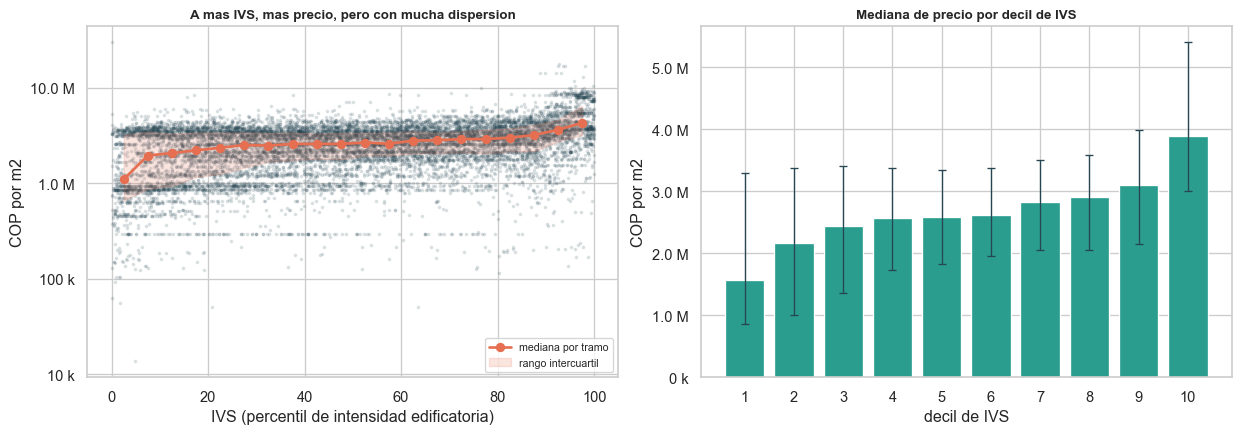

,manzanas,mediana,p25,p75,salto_vs_decil_anterior
ivs,,,,,
1,3802,1574000.0,860000.0,3300000.0,NaN
2,3802,2160000.0,1000000.0,3380804.0,0.0
3,3802,2440000.0,1352500.0,3400000.0,0.0
4,3801,2570000.0,1730000.0,3370000.0,0.0
5,3802,2580000.0,1820000.0,3337250.0,0.0
6,3802,2620000.0,1950000.0,3370000.0,0.0
7,3801,2820000.0,2050000.0,3500000.0,0.0
8,3802,2900000.0,2052500.0,3578000.0,0.0
9,3802,3100000.0,2150000.0,3990000.0,0.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
sub = con_valor.sample(min(12000, len(con_valor)), random_state=C.SEED)
ax.scatter(sub["ivs"], sub["cop_m2"], s=3, alpha=.12, color=AZUL)
bins = np.arange(0, 101, 5)
g = con_valor.groupby(pd.cut(con_valor["ivs"], bins), observed=True)["cop_m2"]
centros = [i.mid for i in g.median().index]
ax.plot(centros, g.median().values, "o-", color=ROJO, lw=2, label="mediana por tramo")
ax.fill_between(centros, g.quantile(.25).values, g.quantile(.75).values,
                color=ROJO, alpha=.18, label="rango intercuartil")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("IVS (percentil de intensidad edificatoria)")
ax.set_ylabel("COP por m2")
ax.set_title("A mas IVS, mas precio, pero con mucha dispersion")
ax.legend(fontsize=8)

ax = axes[1]
deciles = con_valor.groupby(pd.qcut(con_valor["ivs"], 10, labels=range(1, 11)),
                            observed=True).agg(
    manzanas=("cop_m2", "size"), mediana=("cop_m2", "median"),
    p25=("cop_m2", lambda s: s.quantile(.25)), p75=("cop_m2", lambda s: s.quantile(.75)))
ax.bar(deciles.index.astype(int), deciles["mediana"], color=VERDE)
ax.errorbar(deciles.index.astype(int), deciles["mediana"],
            yerr=[deciles["mediana"] - deciles["p25"], deciles["p75"] - deciles["mediana"]],
            fmt="none", ecolor=AZUL, capsize=3, lw=1)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("decil de IVS")
ax.set_ylabel("COP por m2")
ax.set_title("Mediana de precio por decil de IVS")
ax.set_xticks(range(1, 11))

fig.tight_layout()
guardar_fig(fig, "fig32_ivs_vs_precio.png")
plt.show()

deciles["salto_vs_decil_anterior"] = deciles["mediana"].pct_change().round(3)
guardar_tabla(deciles.round(0), "t21_precio_por_decil_ivs.csv")
deciles.round(0)

### El ajuste

Dos formas de traducir IVS a pesos:

- **Isotónica**: solo impone que el precio no baje cuando sube el IVS. No supone
  ninguna forma concreta de la curva.
- **Log-lineal**: una recta sobre el logaritmo del precio. Menos flexible pero
  se resume en una frase: cuántos puntos de IVS hacen falta para duplicar el
  precio.

In [9]:
iso = IsotonicRegression(out_of_bounds="clip").fit(tr["ivs"], tr["log_cop"])
b, a = np.polyfit(tr["ivs"], tr["log_cop"], 1)   # log10(precio) = a + b * ivs

def ivs_a_pesos(ivs, metodo="isotonica"):
    "Convierte IVS (0-100) a COP/m2. Acepta un numero suelto o un arreglo."
    escalar = np.isscalar(ivs)
    x = np.atleast_1d(np.asarray(ivs, dtype=float))
    log = iso.predict(x) if metodo == "isotonica" else a + b * x
    salida = 10 ** log
    return float(salida[0]) if escalar else salida

def errores(reales, estimados):
    "Error porcentual y R2 sobre el logaritmo: son criterios distintos y conviene ver ambos."
    ape = np.abs(estimados - reales) / reales
    lr, le = np.log10(reales), np.log10(estimados)
    r2 = 1 - ((lr - le) ** 2).sum() / ((lr - lr.mean()) ** 2).sum()
    return {"error_mediano_pct": round(100 * np.median(ape), 1),
            "dentro_de_±30%": round(100 * np.mean(ape <= .30), 1),
            "r2_log": round(r2, 3)}

filas = []
for nombre, metodo in [("Isotonica", "isotonica"), ("Log-lineal", "lineal")]:
    for etapa, d in [("ajuste (855 sectores)", tr), ("prueba (285 sectores no vistos)", te)]:
        filas.append(dict(metodo=nombre, conjunto=etapa,
                          **errores(d["cop_m2"].values, ivs_a_pesos(d["ivs"], metodo))))
# referencia: no usar el IVS, asignar a todos la mediana de la ciudad
mediana_ciudad = tr["cop_m2"].median()
filas.append(dict(metodo="Mediana de la ciudad", conjunto="prueba (285 sectores no vistos)",
                  **errores(te["cop_m2"].values, np.full(len(te), mediana_ciudad))))

tabla_error = pd.DataFrame(filas)
guardar_tabla(tabla_error, "t22_error_calibracion.csv", index=False)

print("duplicar el precio exige subir %.0f puntos de IVS" % (np.log10(2) / b))
print("precio estimado en IVS 50: %s   |  en IVS 95: %s"
      % (pesos(ivs_a_pesos(50)), pesos(ivs_a_pesos(95))))
tabla_error

duplicar el precio exige subir 84 puntos de IVS
precio estimado en IVS 50: 2.3 M   |  en IVS 95: 3.5 M


,metodo,conjunto,error_mediano_pct,dentro_de_±30%,r2_log
0,Isotonica,ajuste (855 sectores),34.4,43.2,0.157
1,Isotonica,prueba (285 sectores no vistos),33.7,43.6,0.134
2,Log-lineal,ajuste (855 sectores),35.4,42.7,0.129
3,Log-lineal,prueba (285 sectores no vistos),34.4,43.8,0.112
4,Mediana de la ciudad,prueba (285 sectores no vistos),29.4,52.3,-0.082


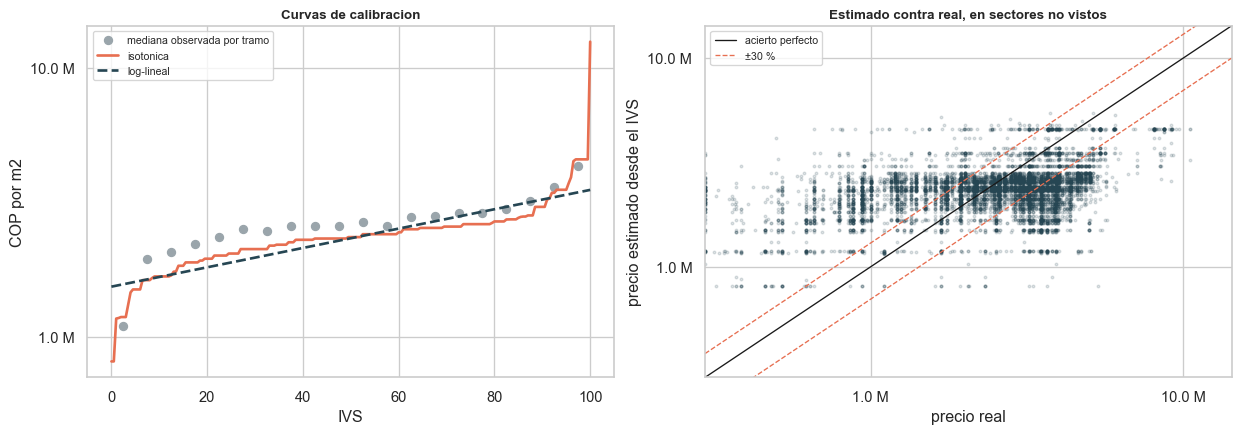

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
rejilla = np.linspace(0, 100, 201)
ax.plot(centros, g.median().values, "o", color=GRIS, label="mediana observada por tramo")
ax.plot(rejilla, ivs_a_pesos(rejilla, "isotonica"), "-", color=ROJO, lw=2, label="isotonica")
ax.plot(rejilla, ivs_a_pesos(rejilla, "lineal"), "--", color=AZUL, lw=2, label="log-lineal")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("IVS")
ax.set_ylabel("COP por m2")
ax.set_title("Curvas de calibracion")
ax.legend(fontsize=8)

ax = axes[1]
est = ivs_a_pesos(te["ivs"], "isotonica")
ax.scatter(te["cop_m2"], est, s=4, alpha=.15, color=AZUL)
lim = [con_valor["cop_m2"].quantile(.01), con_valor["cop_m2"].quantile(.999)]
ax.plot(lim, lim, "-", color="k", lw=1, label="acierto perfecto")
ax.plot(lim, [l * 1.3 for l in lim], "--", color=ROJO, lw=1, label="±30 %")
ax.plot(lim, [l * 0.7 for l in lim], "--", color=ROJO, lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("precio real")
ax.set_ylabel("precio estimado desde el IVS")
ax.set_title("Estimado contra real, en sectores no vistos")
ax.legend(fontsize=8)

fig.tight_layout()
guardar_fig(fig, "fig33_calibracion.png")
plt.show()

### Tabla de conversión

Para usar la calibración sin ejecutar nada: qué precio corresponde a cada nivel
de IVS.

In [11]:
niveles = [5, 10, 25, 50, 75, 90, 95, 99]
conversion = pd.DataFrame({
    "ivs": niveles,
    "cop_m2_estimado": [round(ivs_a_pesos(n)) for n in niveles],
})
conversion["legible"] = conversion["cop_m2_estimado"].map(pesos)
reales = con_valor.groupby(pd.cut(con_valor["ivs"], [n - 2.5 for n in niveles] + [101],
                                  labels=niveles), observed=True)["cop_m2"].median()
conversion["cop_m2_observado"] = conversion["ivs"].map(reales).round(0)
guardar_tabla(conversion, "t23_conversion_ivs_pesos.csv", index=False)
conversion

,ivs,cop_m2_estimado,legible,cop_m2_observado
0,5,1501669,1.5 M,1680000.0
1,10,1677976,1.7 M,2150000.0
2,25,2041385,2.0 M,2550000.0
3,50,2349685,2.3 M,2680000.0
4,75,2624991,2.6 M,2999000.0
5,90,3042282,3.0 M,3454657.0
6,95,3522314,3.5 M,3700000.0
7,99,4569018,4.6 M,4500000.0


### Dónde falla la calibración

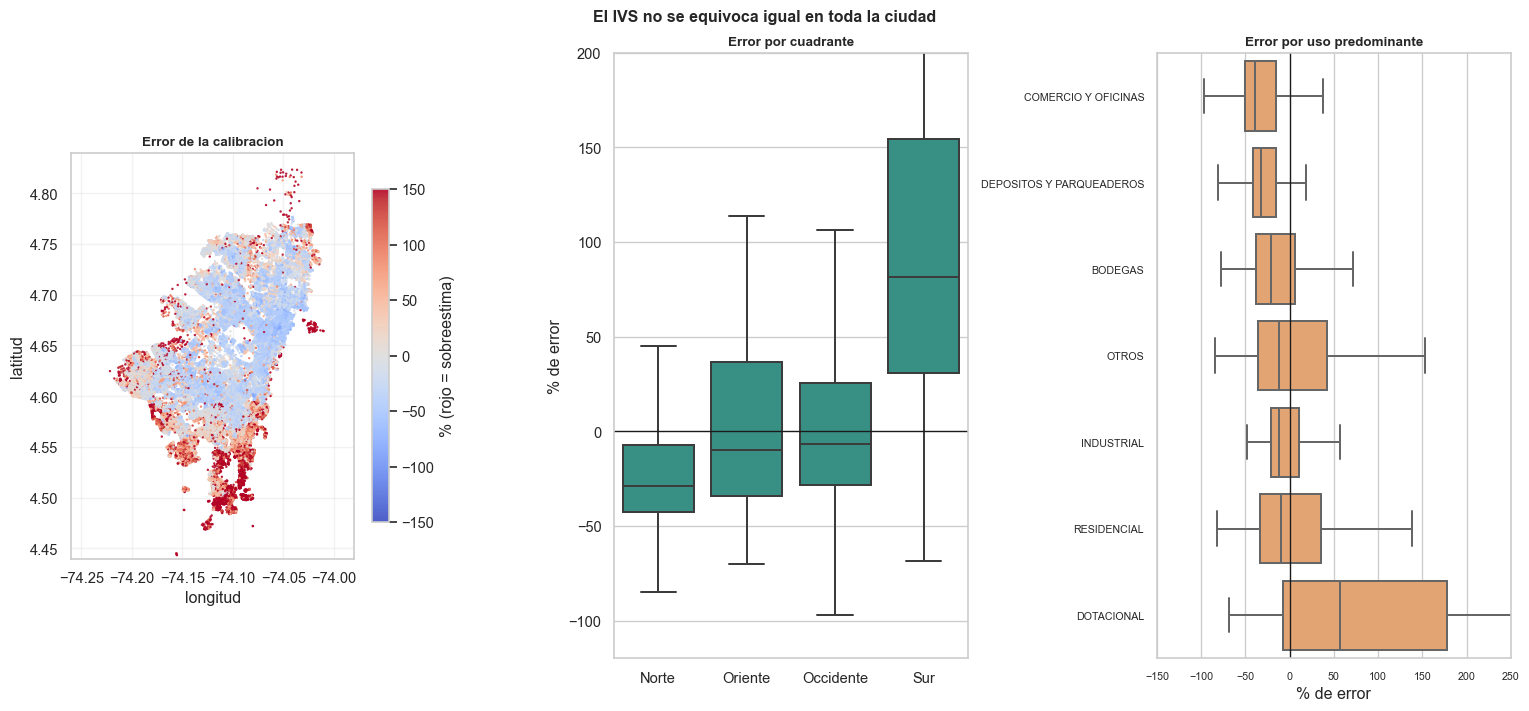

,manzanas,error_mediano_pct,precio_mediano
cuadrante,,,
Norte,14851,-29.1,3500000.0
Occidente,16229,-6.7,2570000.0
Oriente,127,-9.9,3269000.0
Sur,6811,81.6,1200000.0


In [12]:
con_valor["estimado"] = ivs_a_pesos(con_valor["ivs"], "isotonica")
con_valor["error_pct"] = 100 * (con_valor["estimado"] - con_valor["cop_m2"]) / con_valor["cop_m2"]

fig, axes = plt.subplots(1, 3, figsize=(16, 7.5))

ax = axes[0]
u = recorte_urbano(con_valor)
sc = ax.scatter(u["lon"], u["lat"], c=u["error_pct"].clip(-150, 150), s=3.2,
                cmap="coolwarm", vmin=-150, vmax=150, alpha=.9, linewidths=0)
formato_mapa(ax, "Error de la calibracion")
ax.set_ylabel("latitud")
fig.colorbar(sc, ax=ax, label="% (rojo = sobreestima)", shrink=.55)

ax = axes[1]
orden = con_valor.groupby("cuadrante")["error_pct"].median().sort_values().index
sns.boxplot(data=con_valor, x="cuadrante", y="error_pct", order=orden, ax=ax,
            showfliers=False, color=VERDE)
ax.axhline(0, color="k", lw=1)
ax.set_ylim(-120, 200)
ax.set_title("Error por cuadrante")
ax.set_xlabel(""); ax.set_ylabel("% de error")

ax = axes[2]
con_uso = con_valor[con_valor["uso"].notna()]
orden_uso = con_uso.groupby("uso")["error_pct"].median().sort_values().index
sns.boxplot(data=con_uso, y="uso", x="error_pct", order=orden_uso, ax=ax,
            showfliers=False, color=NARANJA)
ax.axvline(0, color="k", lw=1)
ax.set_xlim(-150, 250)
ax.set_title("Error por uso predominante")
ax.set_ylabel(""); ax.set_xlabel("% de error")
ax.tick_params(labelsize=8)

fig.suptitle("El IVS no se equivoca igual en toda la ciudad", fontsize=12, fontweight="bold")
fig.tight_layout()
guardar_fig(fig, "fig34_errores_calibracion.png")
plt.show()

resumen_error = con_valor.groupby("cuadrante").agg(
    manzanas=("error_pct", "size"),
    error_mediano_pct=("error_pct", "median"),
    precio_mediano=("cop_m2", "median")).round(1)
guardar_tabla(resumen_error, "t24_error_por_cuadrante.csv")
resumen_error

### ¿Y si en vez del IVS se usa la ubicación?

El IVS resume **lo construido**. El valor de referencia es el precio del
**terreno**, que lo fijan la ubicación y la norma urbanística. Vale la pena ver
cuál de las dos cosas se acerca más al precio.

In [13]:
from scipy.stats import spearmanr

filas = []
for v in C.FEATURES_UBICACION + ["ivs"]:
    r_ = spearmanr(con_valor[v], con_valor["cop_m2"]).correlation
    filas.append({"variable": v, "spearman_con_precio": round(r_, 3), "abs": abs(r_)})
comparativa = pd.DataFrame(filas).sort_values("abs", ascending=False).drop(columns="abs")
guardar_tabla(comparativa, "t28_correlacion_variables_precio.csv", index=False)

rho_ivs = comparativa.loc[comparativa["variable"] == "ivs", "spearman_con_precio"].iloc[0]
mejor = comparativa.iloc[0]
n_mejores = int((comparativa["spearman_con_precio"].abs() > abs(rho_ivs)).sum())
print("mayor correlacion con el precio: %s (%.3f)" % (mejor["variable"], mejor["spearman_con_precio"]))
print("el IVS queda en %.3f; lo superan %d de las %d variables de ubicacion"
      % (rho_ivs, n_mejores, len(C.FEATURES_UBICACION)))
comparativa

mayor correlacion con el precio: dist_eje_financiero_km (-0.732)
el IVS queda en 0.327; lo superan 7 de las 12 variables de ubicacion


,variable,spearman_con_precio
3,dist_eje_financiero_km,-0.732
8,azimut_cos,0.668
1,lat,0.588
4,dist_aeropuerto_km,-0.567
11,dist_vecino_8_km,0.403
9,vecinos_500m,-0.393
10,vecinos_1km,-0.346
12,ivs,0.327
6,dist_cerros_km,-0.295
0,lon,0.288


## 5. Dónde se está valorizando la ciudad (2017-2026)

Esta es la pregunta que el pipeline no podía responder: no dónde vale más el
suelo, sino **dónde está subiendo más rápido**.

Los valores son **nominales**. Como la inflación afecta a todas las manzanas por
igual, lo interesante es la valorización **relativa a la mediana de la ciudad**:
esa comparación no depende de la inflación. Si quieres verlo en términos reales,
fija `INFLACION_ANUAL_PROM` en la celda de parámetros.

In [14]:
serie = vref[vref["anio"].between(ANIO_BASE, ANIO)]
ciudad = serie.groupby("anio")["cop_m2"].median()
anios_span = ANIO - ANIO_BASE
cagr_ciudad = (ciudad[ANIO] / ciudad[ANIO_BASE]) ** (1 / anios_span) - 1

ancha = serie.pivot_table(index="manzana", columns="anio", values="cop_m2")
ancha = ancha.dropna(subset=[ANIO_BASE, ANIO])
ancha = ancha[(ancha[ANIO_BASE] > 0) & (ancha[ANIO] > 0)]
crec = pd.DataFrame({
    "cop_m2_%d" % ANIO_BASE: ancha[ANIO_BASE],
    "cop_m2_%d" % ANIO: ancha[ANIO],
    "cagr": (ancha[ANIO] / ancha[ANIO_BASE]) ** (1 / anios_span) - 1,
})
crec["vs_ciudad"] = crec["cagr"] - cagr_ciudad
crec = crec.reset_index()

datos_crec = mz.merge(crec, on="manzana", how="inner").merge(uso, on="manzana", how="left")

print("mediana de la ciudad: %s (%d)  ->  %s (%d)"
      % (pesos(ciudad[ANIO_BASE]), ANIO_BASE, pesos(ciudad[ANIO]), ANIO))
print("crecimiento anual compuesto de la ciudad: %.1f%% nominal" % (100 * cagr_ciudad))
if INFLACION_ANUAL_PROM:
    print("descontando %.1f%% de inflacion: %.1f%% real"
          % (100 * INFLACION_ANUAL_PROM, 100 * (cagr_ciudad - INFLACION_ANUAL_PROM)))
print("manzanas con serie completa %d-%d: %d" % (ANIO_BASE, ANIO, len(datos_crec)))

tabla_ciudad = ciudad.to_frame("cop_m2_mediano").assign(
    variacion_anual=ciudad.pct_change().round(3)).round(0)
guardar_tabla(tabla_ciudad, "t25_serie_ciudad.csv")
tabla_ciudad

mediana de la ciudad: 1.2 M (2017)  ->  2.6 M (2026)
crecimiento anual compuesto de la ciudad: 8.9% nominal
manzanas con serie completa 2017-2026: 37552


,cop_m2_mediano,variacion_anual
anio,,
2017,1200000.0,NaN
2018,1400000.0,0.0
2019,1480000.0,0.0
2020,1700000.0,0.0
2021,1900000.0,0.0
2022,1900000.0,0.0
2023,2050000.0,0.0
2024,2150000.0,0.0
2025,2360000.0,0.0


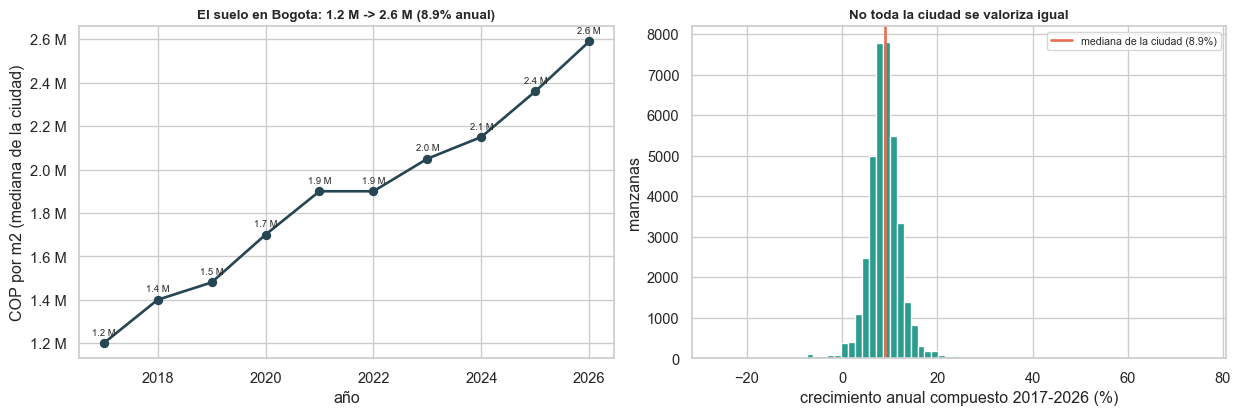

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.plot(ciudad.index, ciudad.values, "o-", color=AZUL, lw=2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("año"); ax.set_ylabel("COP por m2 (mediana de la ciudad)")
ax.set_title("El suelo en Bogota: %s -> %s (%.1f%% anual)"
             % (pesos(ciudad[ANIO_BASE]), pesos(ciudad[ANIO]), 100 * cagr_ciudad))
for x, y in zip(ciudad.index, ciudad.values):
    ax.annotate(pesos(y), (x, y), fontsize=7, xytext=(0, 6), textcoords="offset points", ha="center")

ax = axes[1]
ax.hist(100 * datos_crec["cagr"], bins=70, color=VERDE)
ax.axvline(100 * cagr_ciudad, color=ROJO, lw=2,
           label="mediana de la ciudad (%.1f%%)" % (100 * cagr_ciudad))
ax.set_xlabel("crecimiento anual compuesto 2017-2026 (%)")
ax.set_ylabel("manzanas")
ax.set_title("No toda la ciudad se valoriza igual")
ax.legend(fontsize=8)

fig.tight_layout()
guardar_fig(fig, "fig35_valorizacion_ciudad.png")
plt.show()

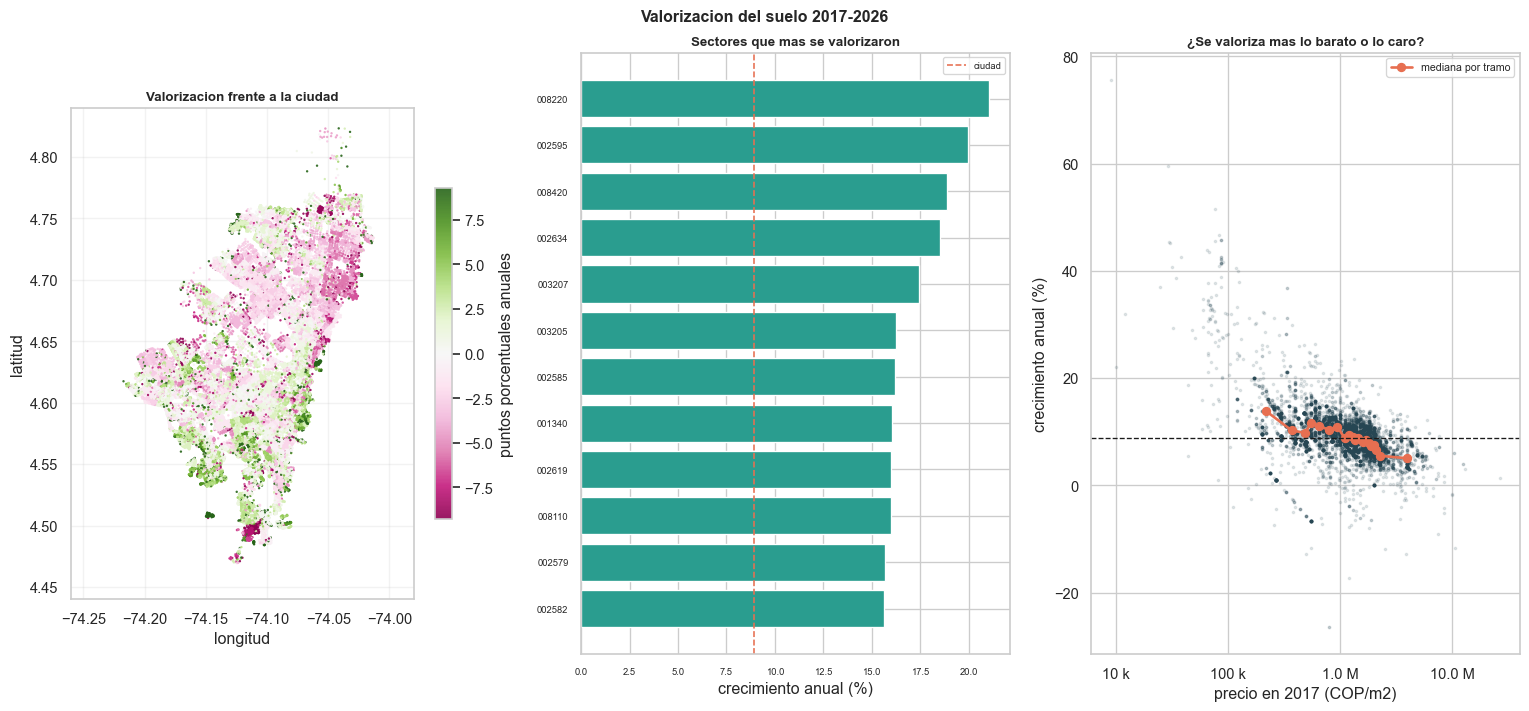

,manzanas,cagr,precio,grupo
sector,,,,
008220,46,21.07,1900000.0,mas se valorizo
002595,66,19.98,876000.0,mas se valorizo
008420,10,18.90,1900000.0,mas se valorizo
002634,14,18.51,876000.0,mas se valorizo
003207,41,17.45,1550000.0,mas se valorizo
003205,26,16.24,1550000.0,mas se valorizo
002585,12,16.18,860000.0,mas se valorizo
001340,32,16.05,458000.0,mas se valorizo
002619,30,16.02,876000.0,mas se valorizo


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 7.5))

ax = axes[0]
u = recorte_urbano(datos_crec)
lim = np.nanpercentile(100 * u["vs_ciudad"], [2, 98])
lim = max(abs(lim[0]), abs(lim[1]))
sc = ax.scatter(u["lon"], u["lat"], c=100 * u["vs_ciudad"], s=3.2, cmap="PiYG",
                vmin=-lim, vmax=lim, alpha=.9, linewidths=0)
formato_mapa(ax, "Valorizacion frente a la ciudad")
ax.set_ylabel("latitud")
fig.colorbar(sc, ax=ax, label="puntos porcentuales anuales", shrink=.55)

ax = axes[1]
sectores = datos_crec.groupby("sector").agg(
    manzanas=("cagr", "size"), cagr=("cagr", "median"),
    precio=("cop_m2_%d" % ANIO, "median")).query("manzanas >= 10")
top = sectores.nlargest(12, "cagr")
ax.barh(top.index[::-1], 100 * top["cagr"][::-1], color=VERDE)
ax.axvline(100 * cagr_ciudad, color=ROJO, ls="--", lw=1.2, label="ciudad")
ax.set_xlabel("crecimiento anual (%)")
ax.set_title("Sectores que mas se valorizaron")
ax.tick_params(labelsize=7)
ax.legend(fontsize=7)

ax = axes[2]
sub = datos_crec.sample(min(12000, len(datos_crec)), random_state=C.SEED)
ax.scatter(sub["cop_m2_%d" % ANIO_BASE], 100 * sub["cagr"], s=3, alpha=.12, color=AZUL)
b_ = datos_crec.groupby(pd.qcut(datos_crec["cop_m2_%d" % ANIO_BASE], 20, duplicates="drop"),
                        observed=True).agg(x=("cop_m2_%d" % ANIO_BASE, "median"),
                                           y=("cagr", "median"))
ax.plot(b_["x"], 100 * b_["y"], "o-", color=ROJO, lw=2, label="mediana por tramo")
ax.axhline(100 * cagr_ciudad, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("precio en %d (COP/m2)" % ANIO_BASE)
ax.set_ylabel("crecimiento anual (%)")
ax.set_title("¿Se valoriza mas lo barato o lo caro?")
ax.legend(fontsize=8)

fig.suptitle("Valorizacion del suelo 2017-2026", fontsize=12, fontweight="bold")
fig.tight_layout()
guardar_fig(fig, "fig36_valorizacion_mapa.png")
plt.show()

ranking = pd.concat([sectores.nlargest(12, "cagr").assign(grupo="mas se valorizo"),
                     sectores.nsmallest(12, "cagr").assign(grupo="menos se valorizo")])
ranking["cagr"] = (100 * ranking["cagr"]).round(2)
guardar_tabla(ranking, "t26_valorizacion_por_sector.csv")
ranking

## 6. Zonas de empresas

El uso predominante responde la pregunta que quedó abierta: dónde están las
manzanas empresariales. Es el uso **predominante de la manzana**, no de cada
predio, así que una oficina aislada en un barrio residencial no aparece aquí.

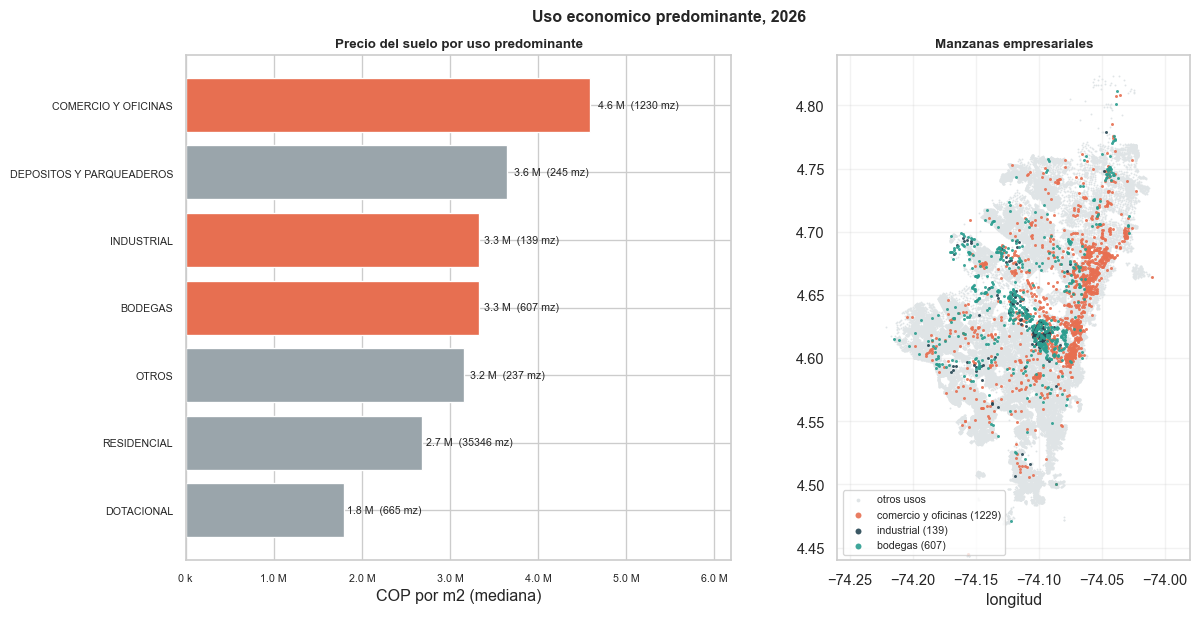

,manzanas,precio_mediano,ivs_mediano,pisos,pct_manzanas
uso,,,,,
COMERCIO Y OFICINAS,1230,4590000.0,86.3,2.4,3.2
DEPOSITOS Y PARQUEADEROS,245,3650000.0,72.9,1.9,0.6
BODEGAS,607,3326000.0,72.6,1.3,1.6
INDUSTRIAL,139,3326000.0,83.7,1.3,0.4
OTROS,237,3159412.0,79.9,1.8,0.6
RESIDENCIAL,35346,2680000.0,47.7,2.3,91.9
DOTACIONAL,665,1800000.0,81.4,2.0,1.7


In [17]:
con_uso = datos[datos["uso"].notna()].copy()
resumen_uso = con_uso.groupby("uso").agg(
    manzanas=("uso", "size"),
    precio_mediano=("cop_m2", "median"),
    ivs_mediano=("ivs", "median"),
    pisos=("pisos_prom_pond", "median")).sort_values("precio_mediano", ascending=False)
resumen_uso["pct_manzanas"] = (100 * resumen_uso["manzanas"] / len(con_uso)).round(1)
guardar_tabla(resumen_uso.round(1), "t27_valor_por_uso.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.15]})

ax = axes[0]
r = resumen_uso.sort_values("precio_mediano")
colores = [ROJO if u in USOS_EMPRESA else GRIS for u in r.index]
ax.barh(r.index, r["precio_mediano"], color=colores)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.set_xlabel("COP por m2 (mediana)")
ax.set_title("Precio del suelo por uso predominante")
for i, (v, n) in enumerate(zip(r["precio_mediano"], r["manzanas"])):
    ax.text(v * 1.02, i, "%s  (%d mz)" % (pesos(v), n), va="center", fontsize=8)
ax.set_xlim(0, r["precio_mediano"].max() * 1.35)
ax.tick_params(labelsize=8)

ax = axes[1]
u = recorte_urbano(con_uso)
otros = u[~u["uso"].isin(USOS_EMPRESA)]
ax.scatter(otros["lon"], otros["lat"], s=2, color="#dfe4e6", linewidths=0, label="otros usos")
for nombre, color in zip(USOS_EMPRESA, [ROJO, AZUL, VERDE]):
    s = u[u["uso"] == nombre]
    ax.scatter(s["lon"], s["lat"], s=5, color=color, linewidths=0, alpha=.9,
               label="%s (%d)" % (nombre.lower(), len(s)))
formato_mapa(ax, "Manzanas empresariales")
ax.legend(fontsize=8, loc="lower left", markerscale=2)

fig.suptitle("Uso economico predominante, %d" % ANIO, fontsize=12, fontweight="bold")
fig.tight_layout()
guardar_fig(fig, "fig37_zonas_empresas.png")
plt.show()

resumen_uso.round(1)

In [18]:
# ¿se valorizan distinto las zonas empresariales?
emp = datos_crec[datos_crec["uso"].notna()].copy()
emp["tipo"] = np.where(emp["uso"].isin(USOS_EMPRESA), "empresarial", "otros usos")
comparacion = emp.groupby("tipo").agg(
    manzanas=("cagr", "size"),
    precio_mediano=("cop_m2_%d" % ANIO, "median"),
    crecimiento_anual_pct=("cagr", lambda s: round(100 * s.median(), 2))).round(0)
comparacion

,manzanas,precio_mediano,crecimiento_anual_pct
tipo,,,
empresarial,1925,4000000.0,8.0
otros usos,35627,2680000.0,9.0


## 7. Resultado y síntesis

Se guarda una tabla por manzana con el precio real, el estimado desde el IVS, el
uso y la valorización, para usarla fuera del notebook.

In [19]:
salida = (datos[["manzana", "sector", "lon", "lat", "ivs", "valor_cat", "cop_m2", "uso"]]
          .merge(crec[["manzana", "cagr", "vs_ciudad"]], on="manzana", how="left"))
salida["cop_m2_estimado_ivs"] = ivs_a_pesos(salida["ivs"], "isotonica").round(0)
salida = salida.rename(columns={"cop_m2": "cop_m2_real_%d" % ANIO,
                                "cagr": "crecimiento_anual",
                                "vs_ciudad": "crecimiento_vs_ciudad"})
salida.to_csv(F_SALIDA, index=False)
print("guardado:", F_SALIDA.name, "|", len(salida), "manzanas")
salida.head()

guardado: manzanas_valor_pesos.csv.gz | 38748 manzanas


,manzana,sector,lon,lat,ivs,valor_cat,cop_m2_real_2026,uso,crecimiento_anual,crecimiento_vs_ciudad,cop_m2_estimado_ivs
0,005635004,005635,-74.115116,4.707818,9.726954,Bajo,3387000.0,RESIDENCIAL,0.060280,-0.028962,1677976.0
1,005635042,005635,-74.112751,4.707911,25.872303,Medio-Bajo,3474000.0,RESIDENCIAL,0.063272,-0.025970,2041385.0
2,006525027,006525,-74.168524,4.681705,89.052338,Alto,1244000.0,RESIDENCIAL,0.065975,-0.023267,3042282.0
3,002527007,002527,-74.108267,4.511395,30.538350,Medio-Bajo,1400000.0,RESIDENCIAL,0.121203,0.031961,2120696.0
4,002527014,002527,-74.107248,4.510175,61.084443,Medio-Alto,1400000.0,RESIDENCIAL,0.121203,0.031961,2512816.0


In [20]:
err_prueba = tabla_error[(tabla_error["metodo"] == "Isotonica") &
                         tabla_error["conjunto"].str.startswith("prueba")].iloc[0]
err_base = tabla_error[tabla_error["metodo"] == "Mediana de la ciudad"].iloc[0]

print("COBERTURA")
print("  %d de %d manzanas del pipeline tienen precio real (%.0f%%)"
      % (cobertura.loc[1, "manzanas"], len(datos), cobertura.loc[1, "porcentaje"]))
print("\nPRECIO DEL SUELO EN %d" % ANIO)
print("  mediana %s | p10 %s | p90 %s"
      % (pesos(con_valor["cop_m2"].median()),
         pesos(np.percentile(con_valor["cop_m2"], 10)),
         pesos(np.percentile(con_valor["cop_m2"], 90))))
print("\nCALIBRACION DEL IVS (sectores no vistos)")
print("  error mediano %.0f%% | dentro de ±30%%: %.0f%% de las manzanas"
      % (err_prueba["error_mediano_pct"], err_prueba["dentro_de_±30%"]))
print("  sin IVS, usando la mediana de la ciudad: error mediano %.0f%%"
      % err_base["error_mediano_pct"])
print("  correlacion de Spearman IVS vs precio: %.3f" % rho)
print("\nVALORIZACION %d-%d" % (ANIO_BASE, ANIO))
print("  la ciudad crecio %.1f%% anual nominal" % (100 * cagr_ciudad))
print("  el 10%% mas dinamico supero a la ciudad en %.1f puntos anuales"
      % (100 * datos_crec["vs_ciudad"].quantile(.9)))
print("\nZONAS EMPRESARIALES")
emp_mz = con_uso[con_uso["uso"].isin(USOS_EMPRESA)]
print("  %d manzanas (%.1f%% de las que tienen uso), precio mediano %s"
      % (len(emp_mz), 100 * len(emp_mz) / len(con_uso), pesos(emp_mz["cop_m2"].median())))

COBERTURA
  38018 de 38748 manzanas del pipeline tienen precio real (98%)

PRECIO DEL SUELO EN 2026
  mediana 2.7 M | p10 940 k | p90 4.4 M

CALIBRACION DEL IVS (sectores no vistos)
  error mediano 34% | dentro de ±30%: 44% de las manzanas
  sin IVS, usando la mediana de la ciudad: error mediano 29%
  correlacion de Spearman IVS vs precio: 0.327

VALORIZACION 2017-2026
  la ciudad crecio 8.9% anual nominal
  el 10% mas dinamico supero a la ciudad en 3.7 puntos anuales

ZONAS EMPRESARIALES
  1976 manzanas (5.1% de las que tienen uso), precio mediano 4.0 M


### Cómo leer esto

- **La calibración del IVS no funciona, y ese es el hallazgo.** Traducir el
  índice a pesos se equivoca más que asignarle a toda manzana la mediana de la
  ciudad. La correlación con el precio existe, pero es débil y no alcanza para
  tasar. El IVS describe **lo construido**; el valor de referencia es el precio
  del **terreno**, que depende de la ubicación y de lo que la norma permite
  construir, no de lo que ya está levantado.
- **Dónde sí sirve el IVS**: para lo que se diseñó, ordenar manzanas por
  intensidad edificatoria. Como estimador de precio, no.
- **Ya no hace falta el proxy.** Con `cop_m2` disponible para el 98 % de las
  manzanas, el modelado del pipeline puede repetirse sobre pesos reales. Varias
  variables de ubicación correlacionan mejor con el precio que el propio IVS,
  así que ese camino tiene más recorrido.
- **La valorización es la pregunta de negocio.** El precio de hoy ya está en el
  mercado; lo que discrimina una decisión es dónde crece por encima de la
  ciudad, que es el mapa de la sección 5. Al ser una comparación relativa, no le
  afecta la inflación.
- **Cuidado con la unidad de análisis.** Todo esto es por manzana. Para decidir
  sobre un lote concreto hace falta el avalúo predial, que no está en estos
  servicios públicos.